# Logistic regression and gradient boosting against Elo

Both model families are trained on 2014-15 to 2019-20 with the day 4 and 5 features, with Elo as log-odds among them. Each is chosen and compared on validation (2020-21, 2021-22) by log loss. Run by `make train`, which writes `reports/models.json`.

In [1]:
import json
import os
from pathlib import Path

os.environ.setdefault("NBA_DATA_DIR", "../data")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from nba_predictor import train as T
from nba_predictor.evaluate import log_loss, paired_log_loss_difference, split
from nba_predictor.model_store import load_model

report = json.loads(Path("../reports/models.json").read_text())
results = pd.DataFrame(report["results"]).T
results.loc["Elo (baseline)"] = pd.Series(report["elo"])
results.sort_values("log_loss")[["log_loss", "brier", "accuracy", "auc", "mean_predicted"]]

,log_loss,brier,accuracy,auc,mean_predicted
Elo (baseline),0.6411,0.2248,0.6359,0.6841,0.5775
logistic C=0.1,0.6418,0.2248,0.6342,0.6856,0.5779
logistic C=10.0,0.6418,0.2248,0.6333,0.6858,0.5779
logistic C=1.0,0.6418,0.2248,0.6329,0.6858,0.5779
boosting depth=2 iters=300,0.6423,0.2250,0.6433,0.6863,0.5787
logistic C=0.01,0.6426,0.2251,0.6346,0.6843,0.5781
boosting depth=2 iters=100,0.6429,0.2254,0.6377,0.6842,0.5806
boosting depth=3 iters=100,0.6441,0.2259,0.6359,0.6822,0.5804
boosting depth=3 iters=300,0.6454,0.2264,0.6372,0.6816,0.5785


In [2]:
keys = ["best", "best_minus_elo_95", "best_boosting", "best_boosting_minus_elo_95"]
{k: report[k] for k in keys}

{'best': 'logistic C=0.1',
 'best_minus_elo_95': [-0.0033, 0.0044],
 'best_boosting': 'boosting depth=2 iters=300',
 'best_boosting_minus_elo_95': [-0.0036, 0.0059]}

**Nothing beats Elo.** The best model, logistic regression at C = 0.1, scores 0.6418 against Elo's 0.6411. The paired interval for the difference (-0.003 to +0.004) straddles zero, and the best boosting model (-0.004 to +0.006) is no different. The eight models are all within 0.004 of each other: the features carry about as much as Elo already does.

## What the logistic regression learned

In [3]:
feats = pd.read_parquet(Path(os.environ["NBA_DATA_DIR"]) / "processed" / "features.parquet")
train, validation, _ = split(feats)
model = load_model(Path("../models/best-ml"), report["model_sha256"]).model
lr = model[-1]
pd.Series(lr.coef_[0], index=T.FEATURES, name="coefficient (per standard deviation)").round(3)

elo_logit           0.649
diff_margin_avg     0.015
diff_win_pct       -0.032
diff_form_margin    0.107
diff_off_rtg        0.099
diff_def_rtg       -0.096
home_rest_days      0.050
away_rest_days      0.002
home_b2b           -0.019
away_b2b            0.101
min_games_played    0.035
no_home             0.016
Name: coefficient (per standard deviation), dtype: float64

In [4]:
p = model.predict_proba(T.matrix(validation))[:, 1]
cases = {
    "away on a back-to-back": (validation["away_b2b"] == 1) & (validation["home_b2b"] == 0),
    "home on a back-to-back": (validation["home_b2b"] == 1) & (validation["away_b2b"] == 0),
    "neither": (validation["away_b2b"] == 0) & (validation["home_b2b"] == 0),
}
rows = []
for name, m in cases.items():
    g, pm = validation[m], p[m.to_numpy()]
    rows.append(
        {
            "case": name,
            "games": len(g),
            "home won": g["home_win"].mean(),
            "Elo": g["elo_prob"].mean(),
            "model": pm.mean(),
            "log loss Elo": log_loss(g["home_win"], g["elo_prob"]),
            "log loss model": log_loss(g["home_win"], pm),
        }
    )
pd.DataFrame(rows).set_index("case").round(3)

,games,home won,Elo,model,log loss Elo,log loss model
case,,,,,,
away on a back-to-back,372,0.589,0.576,0.622,0.638,0.640
home on a back-to-back,282,0.465,0.577,0.545,0.650,0.651
neither,1543,0.542,0.578,0.573,0.640,0.640


- **The model learned back-to-backs in the right direction.** It moves the home probability up to 62% when only the away team is on a back-to-back and down to 54.5% when only the home team is. In validation those games went 58.9% and 46.5%.
- **But it also carries the old home edge.** It predicts 57.8% home wins overall, against 54.4% actual. So when the away team is tired it overshoots, and the gain is lost. Elo's log-odds dominate the coefficients (0.65 per standard deviation against 0.11 or less for everything else), and that's where the old home edge comes from.

## Dead end: weight recent training seasons more

If the model learned the home edge mostly from recent seasons, the bias might shrink. The half-life is a model setting, so it's chosen on validation like C.

In [5]:
age = (2019 - train["season"].str[:4].astype(int)).to_numpy()
rows = []
for half_life in (None, 4, 2, 1, 0.5):
    w = np.ones(len(train)) if half_life is None else 0.5 ** (age / half_life)
    m = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
    m.fit(T.matrix(train), train["home_win"], logisticregression__sample_weight=w)
    pv = m.predict_proba(T.matrix(validation))[:, 1]
    diff = paired_log_loss_difference(validation["home_win"], pv, validation["elo_prob"])
    rows.append(
        {
            "half-life (seasons)": half_life or "none",
            "log loss": log_loss(validation["home_win"], pv),
            "mean predicted": pv.mean(),
            "minus Elo, 95%": diff,
        }
    )
pd.DataFrame(rows).round(4)

,half-life (seasons),log loss,mean predicted,"minus Elo, 95%"
0,none,0.6418,0.5779,"[-0.0033, 0.0044]"
1,4,0.6415,0.5778,"[-0.0036, 0.0042]"
2,2,0.6417,0.5773,"[-0.0038, 0.0046]"
3,1,0.6425,0.5747,"[-0.0035, 0.0059]"
4,0.5,0.6441,0.5673,"[-0.0026, 0.0087]"


It doesn't work. The mean prediction hardly moves (57.8% down to 56.7% at the shortest half-life), and log loss gets worse as the data thins out. The home edge sits in Elo's log-odds, which carry a 60-point bonus tuned on the old seasons, so reweighting rows can't remove it.

## Calibration on validation

,elo,model,won
elo_prob,,,
"(0.127, 0.35]",0.282,0.267,0.307
"(0.35, 0.428]",0.391,0.380,0.368
"(0.428, 0.488]",0.459,0.446,0.385
"(0.488, 0.541]",0.516,0.514,0.472
"(0.541, 0.588]",0.566,0.570,0.498
"(0.588, 0.63]",0.611,0.616,0.576
"(0.63, 0.678]",0.653,0.661,0.597
"(0.678, 0.728]",0.703,0.711,0.706
"(0.728, 0.787]",0.756,0.765,0.706


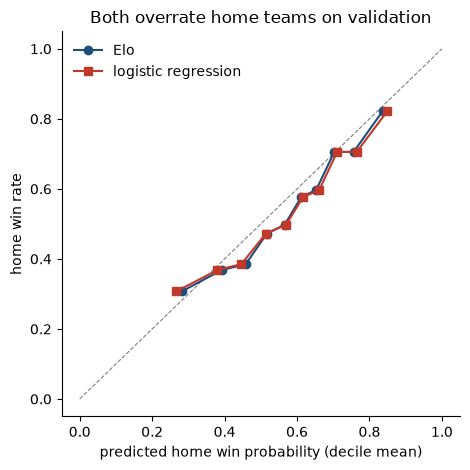

In [6]:
q = pd.qcut(validation["elo_prob"], 10)
frame = validation.assign(model=p)
cal = frame.groupby(q, observed=True).agg(
    elo=("elo_prob", "mean"), model=("model", "mean"), won=("home_win", "mean")
)
fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.plot([0, 1], [0, 1], color="grey", lw=0.8, ls="--")
ax.plot(cal["elo"], cal["won"], "o-", label="Elo", color="#1f4e79")
ax.plot(cal["model"], cal["won"], "s-", label="logistic regression", color="#c0392b")
ax.set_xlabel("predicted home win probability (decile mean)")
ax.set_ylabel("home win rate")
ax.set_title("Both overrate home teams on validation")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/calibration_validation.png", dpi=150)
cal.round(3)

## Decision for now

No model has a measurable edge over Elo, so **Elo stays the reference**. The logistic regression is saved (`models/best-ml`) for the day 8 ablation. What the CLI uses is decided after that. The simpler model wins unless a feature set beats Elo with an interval clear of zero.